<a href="https://colab.research.google.com/github/Ppcat99/Data-Science_project_Parth-Patel/blob/main/Medicare%20Utilization%20%26%20Cost%20Analysis%20by%20State.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

file_name = next(iter(uploaded))
med = pd.read_csv(io.BytesIO(uploaded[file_name]))

med.head()
# Download the MUP_PHY_P05_V10_D24_GEO.csv file
# Wait for it to download the csv into this google colab

Saving MUP_PHY_R26_P05_V10_D24_Geo.csv to MUP_PHY_R26_P05_V10_D24_Geo (2).csv


/tmp/ipykernel_833/3335970327.py:8: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  med = pd.read_csv(io.BytesIO(uploaded[file_name]))


,Rndrng_Prvdr_Geo_Lvl,Rndrng_Prvdr_Geo_Cd,Rndrng_Prvdr_Geo_Desc,HCPCS_Cd,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Rndrng_Prvdrs,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,National,NaN,National,0001U,Red blood cell typing,N,O,7,100,100.0,100,881.466600,525.950400,525.950400,705.600000
1,National,NaN,National,0002M,"Molecular pathology test for liver disease, in...",N,O,6,416,426.0,426,508.519624,491.465023,484.618333,486.614953
2,National,NaN,National,0003M,"Molecular pathology test for liver disease, in...",N,O,24,8635,8998.0,8998,515.495073,490.235042,484.595947,487.695770
3,National,NaN,National,0005U,Test for detecting genes associated with prost...,N,O,3,15557,15705.0,15705,995.007202,744.017408,744.017408,744.800000
4,National,NaN,National,00100,Anesthesia for procedure on saliva gland,N,F,7658,6284,9341.0,9340,2198.127103,210.499720,165.519569,164.328563


In [ ]:
# Step 1: Identify the headlines
# Rndrng_Prvdr_Geo_Lvl: provider geography level, such as national/state/local grouping.
# Rndrng_Prvdr_Geo_Cd: the code for that geography level.
# Rndrng_Prvdr_Geo_Desc: the text description of the geography.
# HCPCS_Cd: the HCPCS procedure/drug code.
# HCPCS_Desc: the plain-English description of the HCPCS code.
# HCPCS_Drug_Ind: drug indicator, usually whether the HCPCS item is a drug.
# Place_Of_Srvc: place of service, such as office or facility.
# Tot_Rndrng_Prvdrs: total number of rendering providers. (doctor, nurse, therapist)
# Tot_Benes: total beneficiaries. # of people get test Serviced (benefinal)
# Tot_Srvcs: total services. total number of people serviced billed
# Tot_Bene_Day_Srvcs: total beneficiary day services.
# Avg_Sbmtd_Chrg: average submitted charge.
# Avg_Mdcr_Alowd_Amt: average Medicare allowed amount.
# Avg_Mdcr_Pymt_Amt: average Medicare payment amount.
# Avg_Mdcr_Stdzd_Amt: average standardized Medicare payment amount.

In [ ]:
med['Rndrng_Prvdr_Geo_Lvl'].value_counts()


,count
Rndrng_Prvdr_Geo_Lvl,
State,254887
National,13463


In [ ]:
med['Rndrng_Prvdr_Geo_Desc'].unique()

array(['National', nan, 'Alabama', 'Alaska', 'Arizona', 'Arkansas',
       'California', 'Colorado', 'Connecticut', 'Delaware',
       'District of Columbia', 'Florida', 'Georgia', 'Hawaii', 'Idaho',
       'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana',
       'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota',
       'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada',
       'New Hampshire', 'New Jersey', 'New Mexico', 'New York',
       'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon',
       'Pennsylvania', 'Rhode Island', 'South Carolina', 'South Dakota',
       'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 'Washington',
       'West Virginia', 'Wisconsin', 'Wyoming', 'American Samoa', 'Guam',
       'Northern Mariana Islands', 'Puerto Rico', 'Virgin Islands',
       'Armed Forces Central/South America', 'Armed Forces Europe',
       'Armed Forces Pacific', 'Unknown', 'Foreign Country'], dtype=object)

In [ ]:
import pandas as pd

national_med = med[med['Rndrng_Prvdr_Geo_Lvl'] == 'National'].copy()
state_med = med[med['Rndrng_Prvdr_Geo_Lvl'] == 'State'].copy()

national_med['Rndrng_Prvdr_Geo_Cd'] = national_med['Rndrng_Prvdr_Geo_Cd'].fillna(0)

state_med = state_med.drop(index=[268352, 268353], errors='ignore')

/tmp/ipykernel_833/1896913400.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  national_med['Rndrng_Prvdr_Geo_Cd'] = national_med['Rndrng_Prvdr_Geo_Cd'].fillna(0)


In [ ]:
national_med = med[med['Rndrng_Prvdr_Geo_Lvl'] == 'National'].copy()
national_med['Rndrng_Prvdr_Geo_Cd'] = national_med['Rndrng_Prvdr_Geo_Cd'].fillna('0')
national_med.head(10)

,Rndrng_Prvdr_Geo_Lvl,Rndrng_Prvdr_Geo_Cd,Rndrng_Prvdr_Geo_Desc,HCPCS_Cd,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Rndrng_Prvdrs,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,National,0,National,0001U,Red blood cell typing,N,O,7,100,100.0,100,881.466600,525.950400,525.950400,705.600000
1,National,0,National,0002M,"Molecular pathology test for liver disease, in...",N,O,6,416,426.0,426,508.519624,491.465023,484.618333,486.614953
2,National,0,National,0003M,"Molecular pathology test for liver disease, in...",N,O,24,8635,8998.0,8998,515.495073,490.235042,484.595947,487.695770
3,National,0,National,0005U,Test for detecting genes associated with prost...,N,O,3,15557,15705.0,15705,995.007202,744.017408,744.017408,744.800000
4,National,0,National,00100,Anesthesia for procedure on saliva gland,N,F,7658,6284,9341.0,9340,2198.127103,210.499720,165.519569,164.328563
5,National,0,National,00100,Anesthesia for procedure on saliva gland,N,O,110,82,134.0,134,1560.052313,167.552164,131.237910,126.835597
6,National,0,National,00102,Anesthesia for plastic repair of lip defect,N,F,34,23,35.0,35,2005.314857,191.127429,148.205714,147.383429
7,National,0,National,00103,Anesthesia for procedure on eyelid,N,F,18315,81627,104892.0,104818,1304.491186,139.766820,108.990390,108.991704
8,National,0,National,00103,Anesthesia for procedure on eyelid,N,O,1054,2353,3958.0,3955,1212.995462,114.855033,89.096784,87.275068
9,National,0,National,00104,Anesthesia for electroshock therapy,N,F,10876,6542,111474.0,111450,813.921258,80.500091,63.289407,62.154172


In [ ]:
state_med.isnull().sum()
state_med[state_med['Rndrng_Prvdr_Geo_Desc'].isnull()]

,Rndrng_Prvdr_Geo_Lvl,Rndrng_Prvdr_Geo_Cd,Rndrng_Prvdr_Geo_Desc,HCPCS_Cd,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Rndrng_Prvdrs,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
13463,State,NaN,NaN,90833,Psychotherapy with evaluation and management v...,N,F,1,25,70.0,70,96.028571,64.395000,51.308000,49.979571
13464,State,NaN,NaN,99223,Initial hospital care with moderate level of m...,N,F,1,26,29.0,29,384.000000,173.991379,133.846897,129.363448
13465,State,NaN,NaN,99232,Subsequent hospital care with moderate levelof...,N,F,1,29,77.0,77,160.000000,79.305844,61.520260,59.436883
13466,State,NaN,NaN,99233,Subsequent hospital care with moderate levelof...,N,F,1,33,238.0,238,240.000000,118.746345,94.387605,91.185966
13467,State,NaN,NaN,99239,"Hospital discharge day management, more than 3...",N,F,1,29,32.0,32,212.250000,114.424688,91.170312,88.604062


In [ ]:
state_med.shape
national_med.shape

(13463, 15)

In [ ]:
state_summary_med = state_med.groupby('Rndrng_Prvdr_Geo_Desc').agg(
    total_services=('Tot_Srvcs', 'sum'),
    total_beneficiaries=('Tot_Benes', 'sum'),
    total_providers=('Tot_Rndrng_Prvdrs', 'sum'),
    avg_submitted_charge=('Avg_Sbmtd_Chrg', 'mean'),
    avg_medicare_allowed=('Avg_Mdcr_Alowd_Amt', 'mean'),
    avg_medicare_paid=('Avg_Mdcr_Pymt_Amt', 'mean')
).reset_index()

pd.set_option('display.max_rows', None)
state_summary_med

,Rndrng_Prvdr_Geo_Desc,total_services,total_beneficiaries,total_providers,avg_submitted_charge,avg_medicare_allowed,avg_medicare_paid
0,Alabama,59022290.8,12522827,554721,1024.039869,247.733230,196.302372
1,Alaska,6866283.3,1252106,90044,2365.623273,292.961828,231.444973
2,American Samoa,36.0,36,1,1370.000000,93.365000,65.888333
3,Arizona,96614299.0,19917871,752926,1522.469639,353.850629,282.052650
4,Arkansas,39077623.4,7235157,344428,1051.403487,285.759787,226.254421
5,Armed Forces Central/South America,22362.0,17915,362,322.077922,47.506216,35.971240
6,Armed Forces Europe,32903.0,18333,877,694.782578,94.815005,75.626918
7,Armed Forces Pacific,62469.0,29840,1207,310.746699,77.671399,60.518599
8,California,369730316.3,73327055,3017130,1868.394924,406.186256,325.028050
9,Colorado,50450257.4,10425690,632187,1470.509805,312.393060,248.792389


In [ ]:
state_summary_med.sort_values('total_services', ascending=False).head(10)

,Rndrng_Prvdr_Geo_Desc,total_services,total_beneficiaries,total_providers,avg_submitted_charge,avg_medicare_allowed,avg_medicare_paid
8,California,369730316.3,73327055,3017130,1868.394924,406.186256,325.028050
13,Florida,369172263.8,63060951,2449780,1696.576256,383.743064,307.064520
51,Texas,276994280.6,54383774,2521615,1743.740277,360.185237,287.544207
38,New York,196337754.6,44300776,2125139,2353.167346,359.652804,286.654100
36,New Jersey,152202079.5,39188516,1034318,2208.041881,332.693984,266.497005
45,Pennsylvania,151234485.4,28631927,1631830,1332.344870,319.138494,255.168517
19,Illinois,143369175.6,28539304,1402976,1728.821536,330.257055,263.241029
39,North Carolina,109488068.4,31459019,1298739,1300.948123,287.002742,228.021234
26,Maryland,105956987.1,18667506,725546,1419.164239,362.291592,289.783925
56,Virginia,97099761.3,20011040,943041,1348.873353,311.941545,247.573337


In [ ]:
state_summary_med['services_per_beneficiary'] = state_summary_med['total_services'] / state_summary_med['total_beneficiaries']
state_summary_med.sort_values('services_per_beneficiary', ascending=False).head(10)

,Rndrng_Prvdr_Geo_Desc,total_services,total_beneficiaries,total_providers,avg_submitted_charge,avg_medicare_allowed,avg_medicare_paid,services_per_beneficiary
13,Florida,369172263.8,63060951,2449780,1696.576256,383.743064,307.064520,5.854213
34,Nevada,33171737.3,5772975,259968,1403.151403,283.614202,224.886392,5.746039
26,Maryland,105956987.1,18667506,725546,1419.164239,362.291592,289.783925,5.676012
33,Nebraska,26859889.6,4752697,273967,1152.947263,255.677268,202.031004,5.651505
49,South Dakota,12579913.3,2272509,130397,787.474073,191.241971,150.880982,5.535694
48,South Carolina,70518322.5,12836777,640367,1363.290744,281.016193,222.694748,5.493460
1,Alaska,6866283.3,1252106,90044,2365.623273,292.961828,231.444973,5.483788
4,Arkansas,39077623.4,7235157,344428,1051.403487,285.759787,226.254421,5.401075
45,Pennsylvania,151234485.4,28631927,1631830,1332.344870,319.138494,255.168517,5.282023
50,Tennessee,93740803.5,18349822,926219,1325.124049,322.775009,256.920375,5.108540


In [ ]:
state_summary_sorted = state_summary_med.sort_values('services_per_beneficiary', ascending=False).reset_index(drop=True)
pd.set_option('display.max_rows', None)
state_summary_sorted
# I realized that "Rndrng_Prvdr_Geo_Desc" has a "Unknown" value let find out

,Rndrng_Prvdr_Geo_Desc,total_services,total_beneficiaries,total_providers,avg_submitted_charge,avg_medicare_allowed,avg_medicare_paid,services_per_beneficiary
0,Florida,369172263.8,63060951,2449780,1696.576256,383.743064,307.064520,5.854213
1,Nevada,33171737.3,5772975,259968,1403.151403,283.614202,224.886392,5.746039
2,Maryland,105956987.1,18667506,725546,1419.164239,362.291592,289.783925,5.676012
3,Nebraska,26859889.6,4752697,273967,1152.947263,255.677268,202.031004,5.651505
4,South Dakota,12579913.3,2272509,130397,787.474073,191.241971,150.880982,5.535694
5,South Carolina,70518322.5,12836777,640367,1363.290744,281.016193,222.694748,5.493460
6,Alaska,6866283.3,1252106,90044,2365.623273,292.961828,231.444973,5.483788
7,Arkansas,39077623.4,7235157,344428,1051.403487,285.759787,226.254421,5.401075
8,Pennsylvania,151234485.4,28631927,1631830,1332.344870,319.138494,255.168517,5.282023
9,Tennessee,93740803.5,18349822,926219,1325.124049,322.775009,256.920375,5.108540


In [ ]:
unknown_med = state_med[state_med['Rndrng_Prvdr_Geo_Desc'] == 'Unknown']
unknown_med.sort_values('Tot_Srvcs', ascending=False).head(10)

,Rndrng_Prvdr_Geo_Lvl,Rndrng_Prvdr_Geo_Cd,Rndrng_Prvdr_Geo_Desc,HCPCS_Cd,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Rndrng_Prvdrs,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
268052,State,9D,Unknown,Q9967,"Low osmolar contrast material, 300-399 mg/ml i...",Y,O,1,257,36200.0,361,1.618785,0.131072,0.102996,0.102996
268050,State,9D,Unknown,J9271,"Injection, pembrolizumab, 1 mg",Y,O,1,12,15800.0,78,151.000000,56.081483,44.678956,44.678956
268043,State,9D,Unknown,J1453,"Injection, fosaprepitant, 1 mg",Y,O,1,12,4200.0,28,1.857143,0.140283,0.111769,0.111769
267998,State,9D,Unknown,99214,Established patient office or other outpatient...,N,O,10,1946,3204.0,3204,198.465765,130.933808,97.946660,93.240243
267996,State,9D,Unknown,99213,Established patient office or other outpatient...,N,O,12,1412,2973.0,2973,137.575146,89.046653,65.792247,65.645163
267977,State,9D,Unknown,97110,Therapy procedure using exercise to develop st...,N,O,2,133,2328.0,1651,46.949609,21.636349,16.914450,17.103020
267853,State,9D,Unknown,36415,Insertion of needle into vein for collection o...,N,O,4,859,1980.0,1978,17.382323,8.579131,8.579131,8.650005
267978,State,9D,Unknown,97112,Therapy procedure to re-educate brain-to-nerve...,N,O,2,114,1939.0,1458,48.941784,28.314693,22.263925,22.578510
268011,State,9D,Unknown,99308,Subsequent nursing facility care with straight...,N,O,2,341,1905.0,1905,109.324651,64.321407,51.093134,49.999297
268041,State,9D,Unknown,J1100,"Injection, dexamethasone sodium phosphate, 1 mg",Y,O,2,92,1790.0,202,2.346369,0.112430,0.089570,0.090207


In [ ]:
total_all_services = state_med['Tot_Srvcs'].sum()
unknown_services = unknown_med['Tot_Srvcs'].sum()
pct_unknown = (unknown_services / total_all_services) * 100
print(f"Unknown accounts for {pct_unknown:.2f}% of all services")

Unknown accounts for 0.00% of all services


In [ ]:
unknown_med[['Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt']].mean()

,0
Avg_Sbmtd_Chrg,249.921615
Avg_Mdcr_Alowd_Amt,91.440825
Avg_Mdcr_Pymt_Amt,71.714831


In [ ]:
national_med[['Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt']].mean()
# According to the national numbers we should keep the unknown because it is a
# important data values

,0
Avg_Sbmtd_Chrg,1924.110456
Avg_Mdcr_Alowd_Amt,428.340460
Avg_Mdcr_Pymt_Amt,345.285718


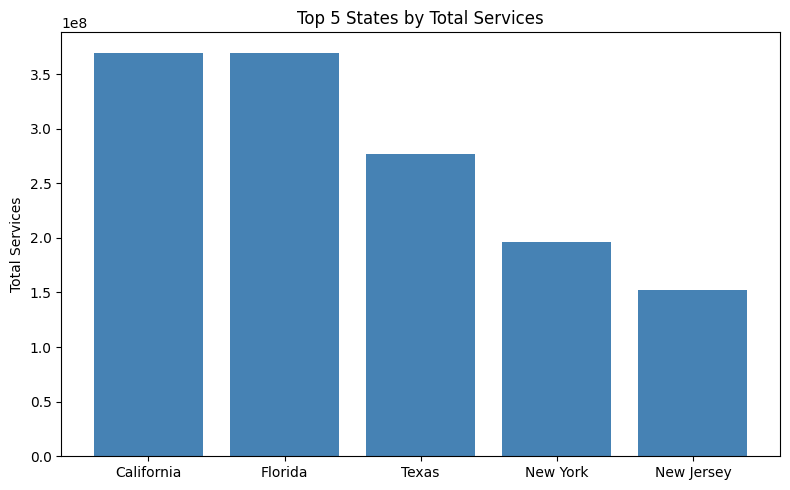

In [ ]:
import matplotlib.pyplot as plt

known_state_summary = state_summary_med[state_summary_med['Rndrng_Prvdr_Geo_Desc'] != 'Unknown']
known_state_summary

top5Services = known_state_summary.sort_values('total_services', ascending = False).head(5)

plt.figure(figsize=(8,5))
plt.bar(top5Services['Rndrng_Prvdr_Geo_Desc'], top5Services['total_services'], color = 'steelblue')
plt.ylabel('Total Services')
plt.title('Top 5 States by Total Services')
plt.tight_layout()
plt.show()
# California and florida got most services

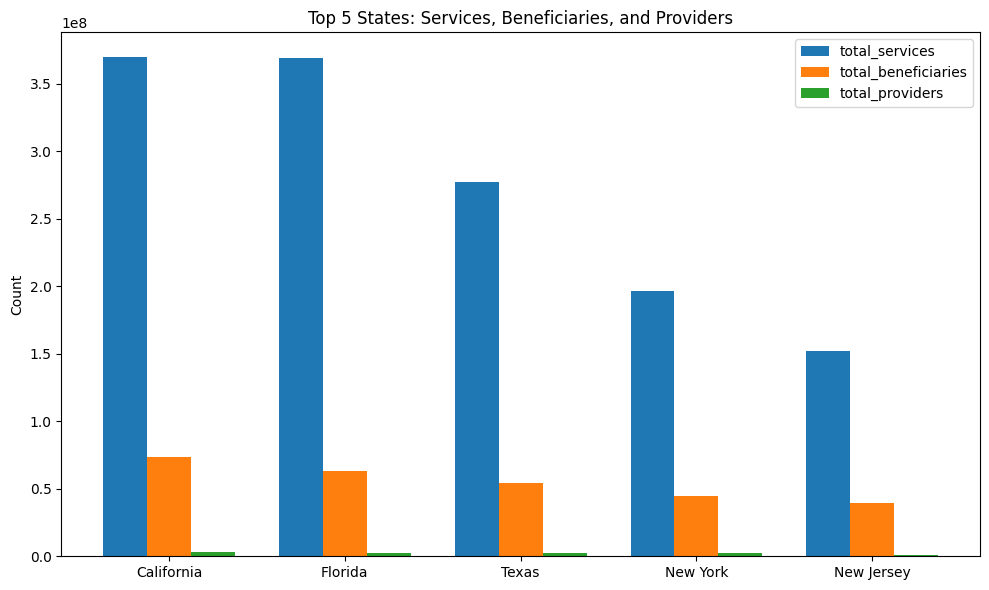

In [ ]:
import numpy as np

categories = ['total_services', 'total_beneficiaries', 'total_providers']
x = np.arange(len(top5Services))
width = 0.25

plt.figure(figsize=(10,6))
for i, cat in enumerate(categories):
    plt.bar(x + i*width, top5Services[cat], width, label=cat)

plt.xticks(x + width, top5Services['Rndrng_Prvdr_Geo_Desc'])
plt.ylabel('Count')
plt.title('Top 5 States: Services, Beneficiaries, and Providers')
plt.legend()
plt.tight_layout()
plt.show()
# Same fundamental happens in this chart more services = more benefits =
# more providers

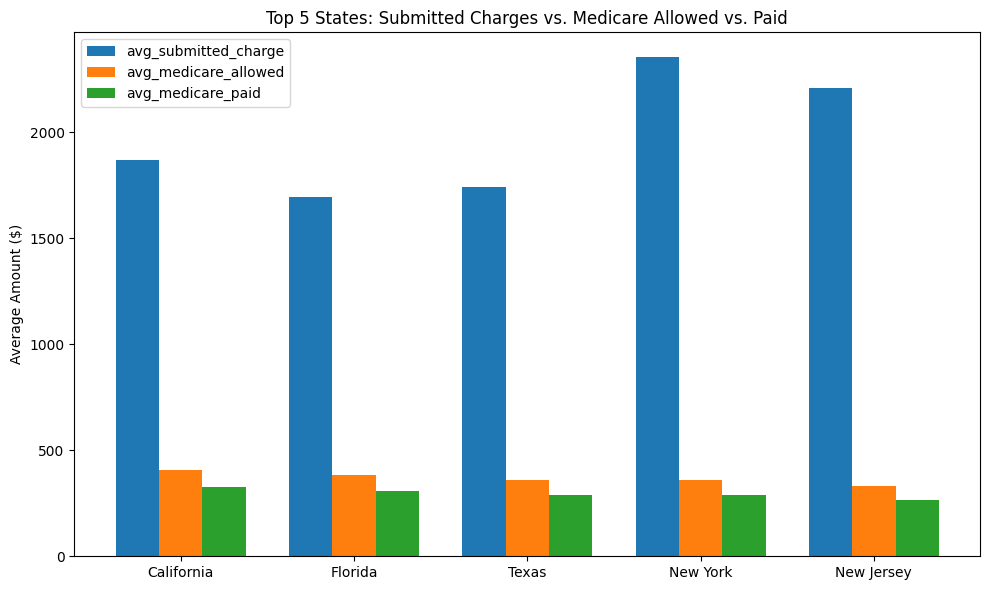

In [ ]:
cost_categories = ['avg_submitted_charge', 'avg_medicare_allowed', 'avg_medicare_paid']
x = np.arange(len(top5Services))

plt.figure(figsize=(10,6))
for i, cat in enumerate(cost_categories):
    plt.bar(x + i*width, top5Services[cat], width, label=cat)

plt.xticks(x + width, top5Services['Rndrng_Prvdr_Geo_Desc'])
plt.ylabel('Average Amount ($)')
plt.title('Top 5 States: Submitted Charges vs. Medicare Allowed vs. Paid')
plt.legend()
plt.tight_layout()
plt.show()

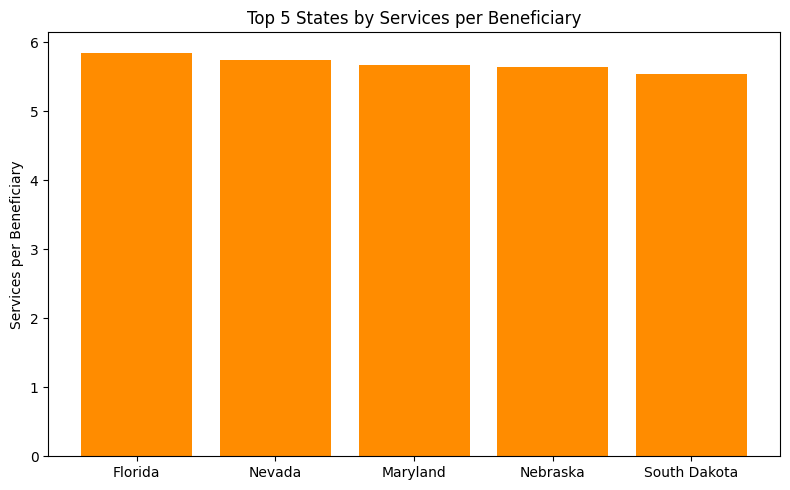

In [ ]:
top5_per_bene = known_state_summary.sort_values('services_per_beneficiary', ascending=False).head(5)

plt.figure(figsize=(8,5))
plt.bar(top5_per_bene['Rndrng_Prvdr_Geo_Desc'], top5_per_bene['services_per_beneficiary'], color='darkorange')
plt.ylabel('Services per Beneficiary')
plt.title('Top 5 States by Services per Beneficiary')
plt.tight_layout()
plt.show()
# In beneficiary it is florida, Nevada, Maryland, Nebraska, and South Dakota.
# So no California

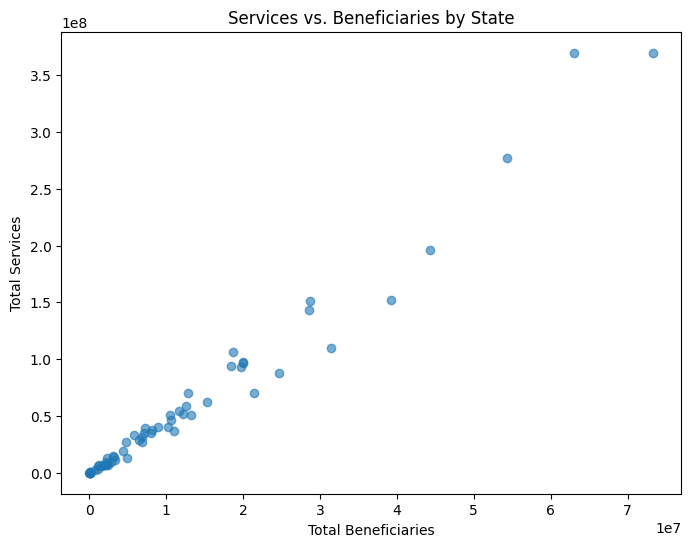

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(known_state_summary['total_beneficiaries'], known_state_summary['total_services'], alpha=0.6)
plt.xlabel('Total Beneficiaries')
plt.ylabel('Total Services')
plt.title('Services vs. Beneficiaries by State')
plt.show()
# Wow more services = more benefits that is postive coorlation

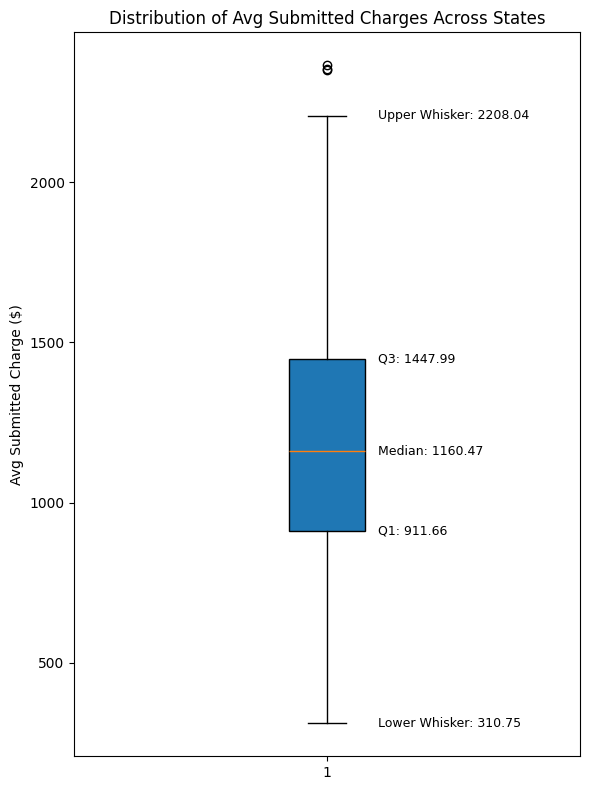

In [ ]:
data = known_state_summary['avg_submitted_charge']

plt.figure(figsize=(6,8))
box = plt.boxplot(data, vert=True, patch_artist=True)

# Calculate the key statistics
median = np.median(data)
q1 = np.percentile(data, 25)
q3 = np.percentile(data, 75)
whisker_low = box['whiskers'][0].get_ydata()[1]
whisker_high = box['whiskers'][1].get_ydata()[1]

# Add text labels next to each key point
stats = {
    'Median': median,
    'Q1': q1,
    'Q3': q3,
    'Lower Whisker': whisker_low,
    'Upper Whisker': whisker_high
}

for label, value in stats.items():
    plt.text(1.1, value, f'{label}: {value:.2f}', va='center', fontsize=9)

plt.title('Distribution of Avg Submitted Charges Across States')
plt.ylabel('Avg Submitted Charge ($)')
plt.tight_layout()
plt.show()
# highest = $2208.04, lowest = $310.75, median = $1160.47

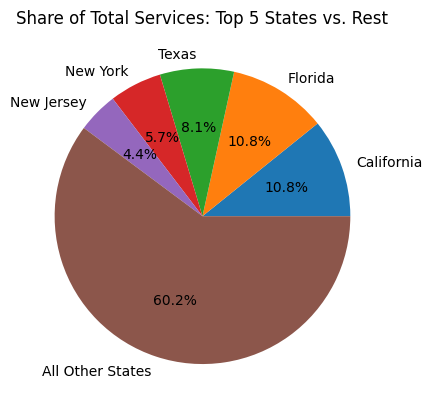

In [ ]:
top5 = known_state_summary.sort_values('total_services', ascending=False).head(5)
others = known_state_summary['total_services'].sum() - top5['total_services'].sum()

labels = list(top5['Rndrng_Prvdr_Geo_Desc']) + ['All Other States']
sizes = list(top5['total_services']) + [others]

plt.pie(sizes, labels=labels, autopct='%1.1f%%')
plt.title('Share of Total Services: Top 5 States vs. Rest')
plt.show()
# out of 60% which are other states 10.8% is florida, 10.8% is california this
# is total services in percentage

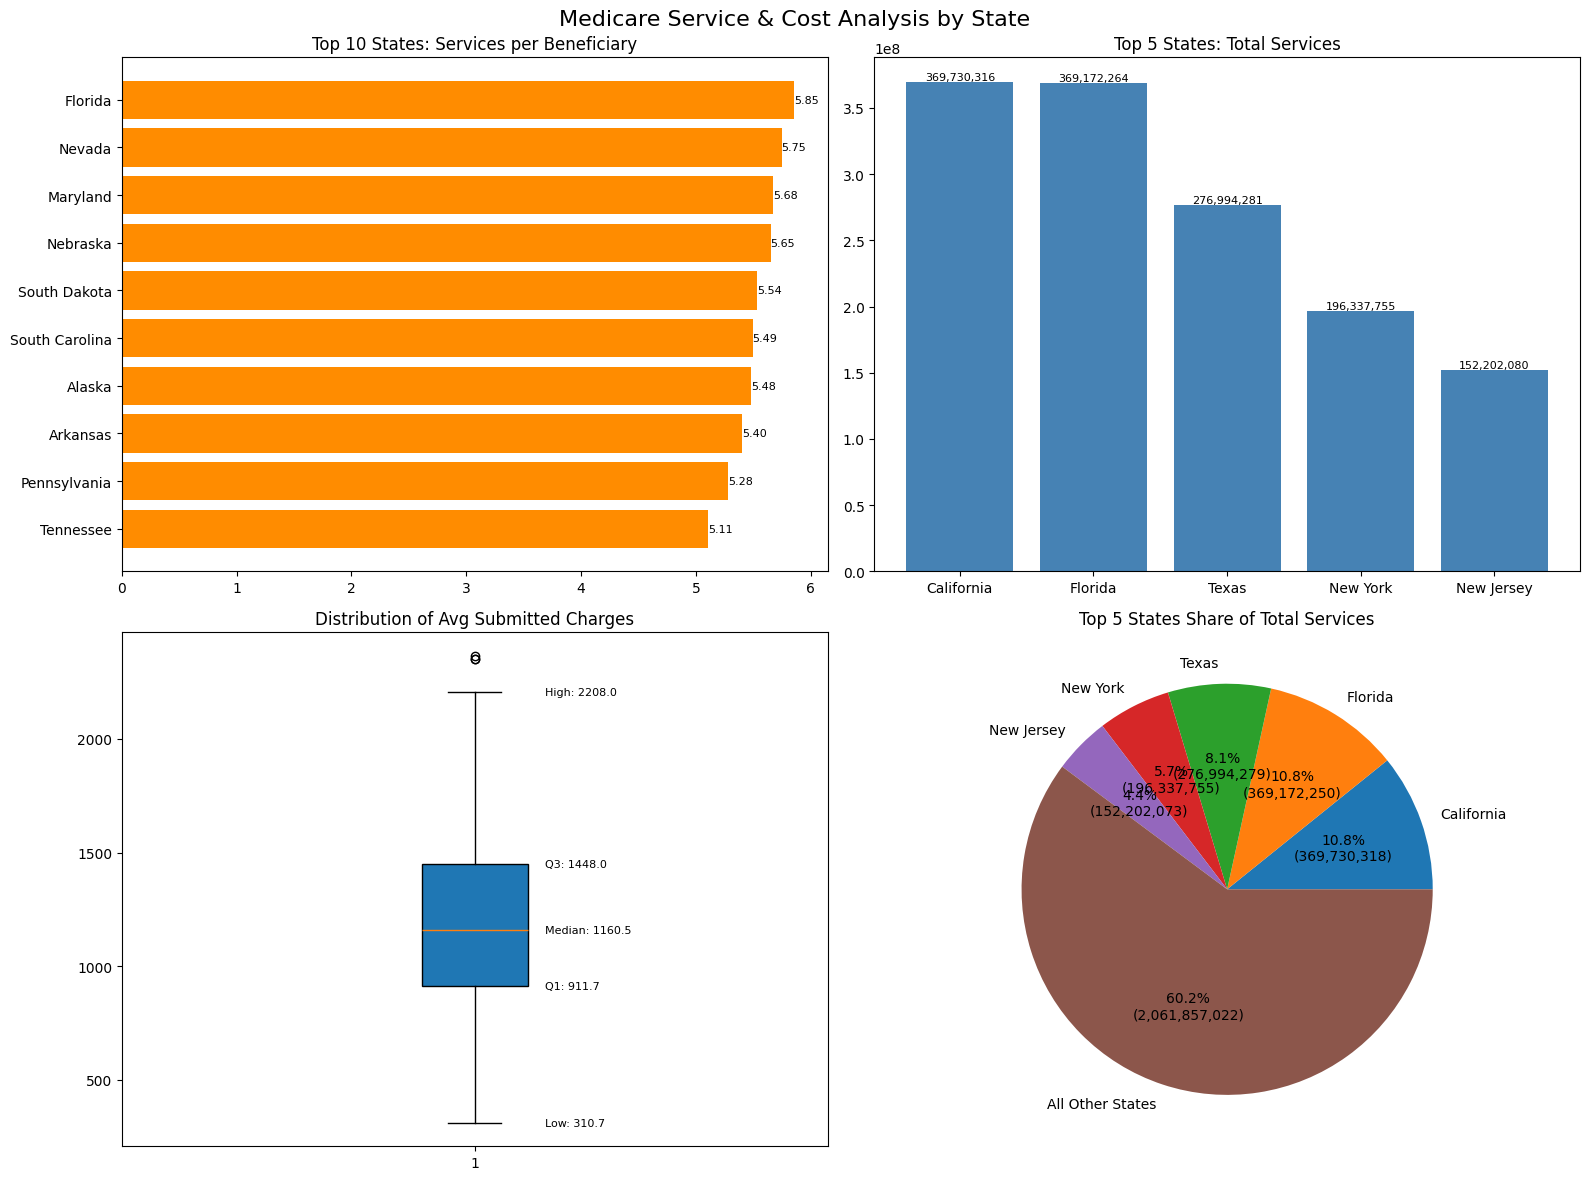

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ---------- Chart 1: Top 10 states by services per beneficiary ----------
top10 = known_state_summary.sort_values('services_per_beneficiary', ascending=False).head(10)
bars1 = axes[0,0].barh(top10['Rndrng_Prvdr_Geo_Desc'], top10['services_per_beneficiary'], color='darkorange')
axes[0,0].invert_yaxis()
axes[0,0].set_title('Top 10 States: Services per Beneficiary')

for bar in bars1:
    width = bar.get_width()
    axes[0,0].text(width, bar.get_y() + bar.get_height()/2, f'{width:.2f}', va='center', ha='left', fontsize=8)

# ---------- Chart 2: Top 5 states by total services ----------
top5 = known_state_summary.sort_values('total_services', ascending=False).head(5)
bars2 = axes[0,1].bar(top5['Rndrng_Prvdr_Geo_Desc'], top5['total_services'], color='steelblue')
axes[0,1].set_title('Top 5 States: Total Services')

for bar in bars2:
    height = bar.get_height()
    axes[0,1].text(bar.get_x() + bar.get_width()/2, height, f'{height:,.0f}', va='bottom', ha='center', fontsize=8, rotation=0)

# ---------- Chart 3: Box plot of charges ----------
box = axes[1,0].boxplot(known_state_summary['avg_submitted_charge'], vert=True, patch_artist=True)
axes[1,0].set_title('Distribution of Avg Submitted Charges')

median = np.median(known_state_summary['avg_submitted_charge'])
q1 = np.percentile(known_state_summary['avg_submitted_charge'], 25)
q3 = np.percentile(known_state_summary['avg_submitted_charge'], 75)
whisker_low = box['whiskers'][0].get_ydata()[1]
whisker_high = box['whiskers'][1].get_ydata()[1]

stats = {'Median': median, 'Q1': q1, 'Q3': q3, 'Low': whisker_low, 'High': whisker_high}
for label, value in stats.items():
    axes[1,0].text(1.1, value, f'{label}: {value:.1f}', va='center', fontsize=8)

# ---------- Chart 4: Pie chart of top 5 share ----------
others = known_state_summary['total_services'].sum() - top5['total_services'].sum()
labels = list(top5['Rndrng_Prvdr_Geo_Desc']) + ['All Other States']
sizes = list(top5['total_services']) + [others]

axes[1,1].pie(sizes, labels=labels, autopct=lambda p: f'{p:.1f}%\n({p*sum(sizes)/100:,.0f})')
axes[1,1].set_title('Top 5 States Share of Total Services')

plt.suptitle('Medicare Service & Cost Analysis by State', fontsize=16)
plt.tight_layout()
plt.show()

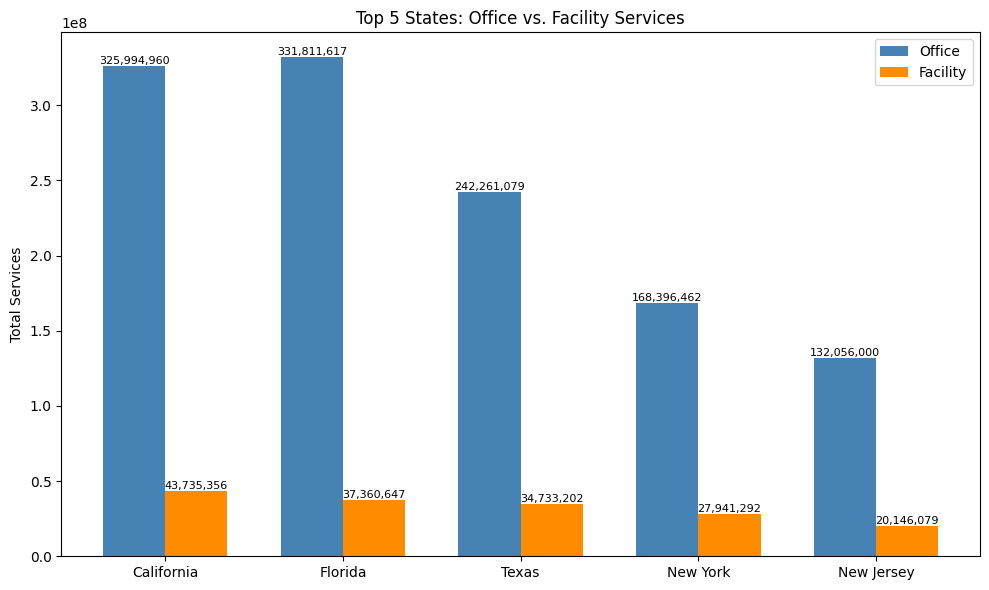

In [ ]:
state_df = med[med['Rndrng_Prvdr_Geo_Lvl'] == 'State'].copy()

place_summary = state_df.groupby(['Rndrng_Prvdr_Geo_Desc', 'Place_Of_Srvc']).agg(
    total_services=('Tot_Srvcs', 'sum')
).reset_index()

# Pick your top 5 states (using the same states as your earlier "top 5 by total services" chart)
top5_states = known_state_summary.sort_values('total_services', ascending=False).head(5)['Rndrng_Prvdr_Geo_Desc'].tolist()

# Filter to just those states, and pivot so Office/Facility become separate columns
place_pivot = place_summary[place_summary['Rndrng_Prvdr_Geo_Desc'].isin(top5_states)]
place_pivot = place_pivot.pivot(index='Rndrng_Prvdr_Geo_Desc', columns='Place_Of_Srvc', values='total_services').fillna(0)

# Reorder to match your top5 ranking
place_pivot = place_pivot.reindex(top5_states)

# Build the grouped bar chart
x = np.arange(len(place_pivot))
width = 0.35

fig, ax = plt.subplots(figsize=(10,6))
bars_o = ax.bar(x - width/2, place_pivot['O'], width, label='Office', color='steelblue')
bars_f = ax.bar(x + width/2, place_pivot['F'], width, label='Facility', color='darkorange')

ax.set_xticks(x)
ax.set_xticklabels(place_pivot.index)
ax.set_ylabel('Total Services')
ax.set_title('Top 5 States: Office vs. Facility Services')
ax.legend()

# Add value labels on top of each bar
for bars in [bars_o, bars_f]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height, f'{height:,.0f}',
                 va='bottom', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# summary of your findings #
#------------------------------------------------------------------------------#
# 1. Population size drives raw totals -> states with the highest total services
# like California and florida are the states with the highest medicare beneficiary
# popluations. Raw totals alone mostly reflect population size, not necessary
# healthcare activities.

# 2. Florida is a genuine a outlier in service by beneficiary -> After doing the
# Caliculation of (service / benefiaries). Florida stood clearly higher than any
# other states and Florida's average medicare patient recives more services than
# typicall patient elsewhere and that pattern is indenpendent to population size.

# 3. Arizona's high raw total is explained by population, not rate. Arizona rank
# high in total services but dropped in top of the services_per_beneficiaries
# rank - indicating its raw number are driven by having many beneficiaries, not
# usually by an higher rate of care per person.

# 4. A small "Unknown" geography category exists which is 0.00% of total services
# as we called it mystery service. It was excluded from the state comparisons but
# found to have a submitted charge ($250) far below from national average is
# $1,924 - suggestion these unattributed services many skew toward lower cost.

# Charges vs medicare payments show a consistant gap nationally - Provides
# submitted charges are substantially higher than the medicare actually allows
# or pays a pattern worth noting if the project's audiance cares about affortiblity
# or billing transparency.

# I did the comparison between office and Facility in Califronia people go more
# in facility than florida but in florida people go do medical services in office

# This is billing/adminstrative data not a clincial data - it shows what was
# billed not underlying health outcomes

# "Average" cost and payment figures are means, which can be pulled by outliers
# nothing the boxplot spread is good way to knowledge this.

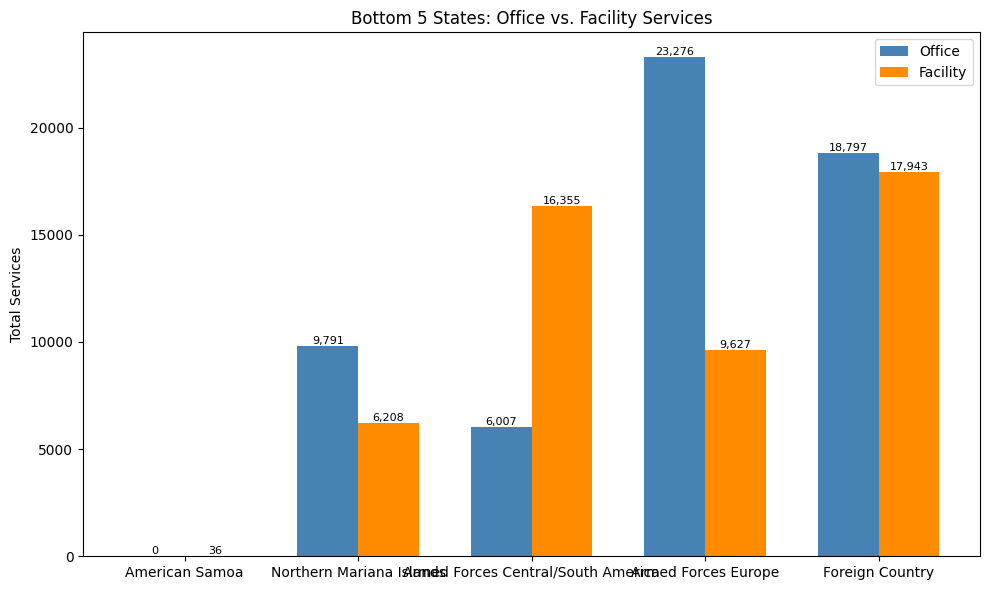

In [ ]:
place_summary = state_df.groupby(['Rndrng_Prvdr_Geo_Desc', 'Place_Of_Srvc']).agg(
    total_services=('Tot_Srvcs', 'sum')
).reset_index()

# Pick bottom 5 states by total services
bottom5_states = known_state_summary.sort_values('total_services', ascending=True).head(5)['Rndrng_Prvdr_Geo_Desc'].tolist()

# Filter to just those states, and pivot so Office/Facility become separate columns
place_pivot = place_summary[place_summary['Rndrng_Prvdr_Geo_Desc'].isin(bottom5_states)]
place_pivot = place_pivot.pivot(index='Rndrng_Prvdr_Geo_Desc', columns='Place_Of_Srvc', values='total_services').fillna(0)

# Reorder to match bottom5 ranking (lowest first)
place_pivot = place_pivot.reindex(bottom5_states)

# Build the grouped bar chart
x = np.arange(len(place_pivot))
width = 0.35

fig, ax = plt.subplots(figsize=(10,6))
bars_o = ax.bar(x - width/2, place_pivot['O'], width, label='Office', color='steelblue')
bars_f = ax.bar(x + width/2, place_pivot['F'], width, label='Facility', color='darkorange')

ax.set_xticks(x)
ax.set_xticklabels(place_pivot.index)
ax.set_ylabel('Total Services')
ax.set_title('Bottom 5 States: Office vs. Facility Services')
ax.legend()

# Add value labels on top of each bar
for bars in [bars_o, bars_f]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height, f'{height:,.0f}',
                 va='bottom', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# BA Questions #
# 1. Which states have the highest total services volume, and does that reflect
# actual need or just popluation size?
# California and Florida lead in raw totals, but this is largely explained by
# having the largest Medicare beneficiary populations — not necessarily higher
# care intensity.

#2. Which state has the highest rate of services per patient, adjusted for population?
# Florida, by a clear margin over every other state — a genuine outlier, not
# just a population effect.

#3. Does Arizona's high raw service count indicate unusually high healthcare
# utilization?
# No — once adjusted for beneficiary count, Arizona drops out of the top ranking,
# showing its raw total is population-driven, not rate-driven.

# 4. How much do providers charge compared to what Medicare actually pays?
# There's a consistent, sizeable gap nationally between Avg_Sbmtd_Chrg and
# Avg_Mdcr_Pymt_Amt — providers bill well above what Medicare allows/pays.

# 5. 5. Is there a data quality concern with unattributed/unknown state records?
# Yes, a small "Unknown" category exists (~0.00% of total services), excluded
# from state comparisons but found to have notably lower average charges than
# the national average — flagged transparently rather than deleted.

# 6. Does care setting (Office vs. Facility) differ meaningfully by state, and could it relate to utilization patterns?
# Yes — Florida shows a higher share of office-based care, California more
# facility-based care. This co-occurs with Florida's high
# services-per-beneficiary rate, though the dataset can't confirm causation.

# 7. What are the limitations of this dataset, and what would you need to
# explain the patterns found?
# This is billing/administrative data only — no diagnosis, demographic, or
# geographic (urban/rural) data. Explaining why Florida or any state shows these
# patterns would require additional datasets (e.g., patient age distribution,
# ICD-10 diagnosis codes, provider density).